In [36]:
# ============================================================
# PAR LAI FROM ALPHAEARTH SATELLITE EMBEDDINGS  |  Random Forest (RF)
# Training/testing: Rema-Kalenga Wildlife Sanctuary (RKWS, field 2021)
# Spatial transfer: Khadimnagar National Park (KNP, field 2022)
# Predictors: GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL (64 bands, A00-A63, 10 m)
# ============================================================


In [37]:
# %% SETUP
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'earthengine-api', 'rasterio', 'xgboost'], check=False)
 
import ee
ee.Authenticate()
ee.Initialize(project='osmgee')
 
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor
 
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [38]:
# %% CONFIG
MODEL_TAG  = 'RF'                  # used in file names and plot labels
MODEL_NAME = 'Random Forest (RF)'
 
RKWS_YEAR = 2021                        # RKWS field campaign year
KNP_YEAR  = 2022                        # KNP field campaign year
EMB_COLLECTION = 'GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL'
EMB_BANDS = [f'A{i:02d}' for i in range(64)]

In [39]:
# Recursive feature elimination on the 64 embedding dimensions.
# Google recommends using all 64 bands together (they are one 64-D vector, not
# individually interpretable). Set USE_RFE = False to keep all 64.
USE_RFE            = True
RFE_MIN_FEATURES   = 3
RFE_STEP           = 4                  # dimensions removed per iteration (64 -> ~16 iterations)
RFE_DROP_THRESHOLD = 0.15               # stop if LOOCV RMSE rises by more than this (LAI units)
 
DRIVE_FOLDER = 'GEE_Exports'            # export folder AND the folder read back from Drive
base = f'/content/drive/MyDrive/{DRIVE_FOLDER}/'

In [40]:
# %% [GEE] STUDY AREAS AND FIELD PLOTS
rema_boundary = ee.FeatureCollection('projects/osmgee/assets/RemaKalenga')
rema_sites    = ee.FeatureCollection('projects/osmgee/assets/RemaSites')
knp_boundary  = ee.FeatureCollection('projects/osmgee/assets/KNP')
knp_sites     = ee.FeatureCollection('projects/osmgee/assets/SitesLocation')
 
def clean_feature(f):
    lon = ee.Number(f.get('XCoord'))
    lat = ee.Number(f.get('YCoord'))
    return ee.Feature(
        ee.Geometry.Point([lon, lat]),
        {'cluster_id': f.get('ClusterID'),
         'par_lai': ee.Number(f.get('MEAN_GAP_F')),
         'longitude': lon,
         'latitude': lat}
    )
 
def make_square_plot(feature):
    # 15 m x 15 m plot centred on the field point
    return feature.setGeometry(feature.geometry().buffer(7.5, 1).bounds())
 
rema_squares = rema_sites.map(clean_feature).map(make_square_plot)
knp_squares  = knp_sites.map(clean_feature).map(make_square_plot)
 
print('RKWS plots:', rema_squares.size().getInfo())
print('KNP plots :', knp_squares.size().getInfo())

RKWS plots: 59
KNP plots : 40


In [41]:
# %% [GEE] ALPHAEARTH EMBEDDING IMAGES
def get_embedding(boundary, year):
    col = (ee.ImageCollection(EMB_COLLECTION)
           .filterBounds(boundary.geometry())
           .filterDate(f'{year}-01-01', f'{year + 1}-01-01'))
    n = col.size().getInfo()
    zones = col.aggregate_array('UTM_ZONE').distinct().getInfo()
    print(f'  {year}: {n} embedding tile(s), UTM zone(s): {zones}')
    if n == 0:
        raise ValueError(f'No embedding tiles found for {year}')
    proj = col.first().select(0).projection()
    return col.mosaic().select(EMB_BANDS).setDefaultProjection(proj).clip(boundary)
 
print('RKWS embedding:')
emb_rema = get_embedding(rema_boundary, RKWS_YEAR)
print('KNP embedding:')
emb_knp = get_embedding(knp_boundary, KNP_YEAR)

RKWS embedding:
  2021: 1 embedding tile(s), UTM zone(s): ['46N']
KNP embedding:
  2022: 1 embedding tile(s), UTM zone(s): ['46N']


In [42]:
# %% [GEE] EXTRACT MEAN EMBEDDING PER 15 m PLOT
id_cols = ['cluster_id', 'par_lai', 'longitude', 'latitude']
 
def extract_plot_means(image, squares, label):
    fc = image.reduceRegions(collection=squares, reducer=ee.Reducer.mean(), scale=10)
    df = pd.DataFrame([f['properties'] for f in fc.getInfo()['features']])
    df = df[id_cols + EMB_BANDS]
    n0 = len(df)
    df = df.dropna(subset=EMB_BANDS + ['par_lai']).reset_index(drop=True)
    print(f'{label}: {len(df)} plots extracted' +
          (f' ({n0 - len(df)} dropped: no embedding data)' if len(df) < n0 else ''))
    return df
 
df_rema = extract_plot_means(emb_rema, rema_squares, 'RKWS')
df_knp  = extract_plot_means(emb_knp,  knp_squares,  'KNP')
df_rema.head()

RKWS: 59 plots extracted
KNP: 40 plots extracted


,cluster_id,par_lai,longitude,latitude,A00,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,A11,A12,A13,A14,A15,A16,A17,A18,A19,A20,A21,A22,A23,A24,A25,A26,A27,A28,A29,A30,A31,A32,A33,A34,A35,A36,A37,A38,A39,A40,A41,A42,A43,A44,A45,A46,A47,A48,A49,A50,A51,A52,A53,A54,A55,A56,A57,A58,A59,A60,A61,A62,A63
0,5,1.803558,91.624580,24.112350,0.111471,-0.081209,0.065255,0.015533,-0.000075,-0.038349,-0.101721,0.173381,-0.061483,0.152647,0.099993,0.022787,-0.395621,-0.016399,-0.178694,0.068941,-0.103708,-0.031985,-0.063368,-0.010779,-0.124567,0.277188,0.234701,-0.087536,0.116864,0.039081,0.064539,0.019437,-0.185903,0.076348,0.114782,0.067429,-0.005902,-0.128598,0.036553,-0.031746,-0.281213,-0.040449,0.059815,-0.190515,0.054940,0.028163,-0.053467,0.338439,0.130806,0.015314,-0.064049,0.172667,0.048551,0.156171,-0.026397,-0.052870,0.079385,-0.011243,0.142767,-0.092583,-0.043764,-0.030465,-0.105771,-0.052175,0.107363,-0.178097,0.031659,0.102288
1,27,1.641758,91.630600,24.165805,0.094337,-0.062250,0.089119,-0.015220,-0.032127,-0.065745,-0.101522,0.168073,-0.064110,0.185423,0.073824,0.022319,-0.369164,-0.053714,-0.115273,0.083991,-0.085533,-0.022789,-0.064699,-0.049075,-0.171400,0.280753,0.218512,-0.096760,0.110691,0.091784,0.065499,-0.002753,-0.121248,0.150671,0.081498,0.056083,0.031675,-0.089238,0.042573,-0.035075,-0.237757,-0.047387,0.096129,-0.175321,0.091912,0.087552,-0.096936,0.370025,0.100327,-0.009382,-0.078251,0.192638,0.040771,0.123731,-0.008274,-0.029844,0.042112,-0.015173,0.156330,-0.140834,-0.033724,-0.060055,-0.093129,-0.047409,0.089450,-0.190358,0.030595,0.143805
2,35,1.769877,91.643603,24.170542,0.109637,-0.061448,0.119457,0.010924,-0.005468,-0.024738,-0.129985,0.166497,-0.069322,0.210722,0.052501,0.072157,-0.376675,-0.061600,-0.122740,0.077819,-0.089230,0.021577,-0.074527,-0.008655,-0.206296,0.284222,0.228530,-0.051323,0.083721,0.028045,0.034721,-0.008826,-0.139323,0.142549,0.055656,0.059326,0.039894,-0.080035,0.041475,0.002150,-0.185909,-0.071893,0.070255,-0.141281,0.052467,0.116752,-0.070199,0.389972,0.120221,0.004696,-0.074777,0.162744,0.041083,0.166431,-0.031420,-0.074419,0.066333,-0.049279,0.152091,-0.145521,-0.054750,-0.054105,-0.122529,-0.027116,0.012372,-0.184906,0.044851,0.084463
3,51,1.275394,91.625308,24.203328,0.084500,-0.082186,0.095908,-0.001658,-0.016653,-0.029905,-0.119719,0.161549,-0.037003,0.148978,0.134664,0.032938,-0.370757,-0.018948,-0.106406,0.106370,-0.036418,-0.068267,-0.128780,-0.057895,-0.186287,0.245933,0.189192,-0.128627,0.068938,0.084819,0.095628,0.005138,-0.157398,0.179992,0.071912,0.026336,-0.012488,-0.077574,-0.005262,-0.012642,-0.256933,0.002928,0.100401,-0.120678,0.089900,0.092607,-0.064553,0.382029,0.091493,-0.029349,-0.031482,0.189370,0.004658,0.103152,-0.012630,-0.066069,0.050583,0.009398,0.193037,-0.099104,-0.045920,-0.050246,-0.078028,-0.032999,0.099293,-0.193845,0.044113,0.163795
4,3,1.444491,91.632832,24.109208,0.125789,-0.120793,0.068035,-0.003453,-0.007464,-0.093500,-0.117844,0.171927,-0.080548,0.228931,0.057005,0.060602,-0.377311,-0.062658,-0.161815,0.063162,-0.094156,0.029339,-0.044323,-0.029477,-0.063999,0.272246,0.243475,-0.062108,0.119830,0.032727,0.070820,0.006814,-0.132049,0.125160,0.110917,0.013819,-0.024045,-0.137451,0.013657,-0.049932,-0.225579,-0.112246,0.115461,-0.195908,0.078492,0.062876,-0.076239,0.318893,0.082188,0.007979,-0.055527,0.206130,0.028439,0.133169,-0.000622,-0.068369,0.063050,-0.051272,0.132687,-0.113578,-0.043570,-0.032969,-0.090441,-0.021561,0.133334,-0.187596,0.040056,0.107555


In [43]:
# %% TRAIN / TEST SPLIT (80/20, same seed as the Sentinel-2 and PlanetScope runs)
X_rema = df_rema[EMB_BANDS]
y_rema = df_rema['par_lai']
 
X_train_rema, X_test_rema, y_train_rema, y_test_rema = train_test_split(
    X_rema, y_rema, test_size=0.2, random_state=42
)
 
print(f'Train: {len(y_train_rema)} plots | Test: {len(y_test_rema)} plots')
print('Test cluster IDs (compare with the Sentinel-2 run):',
      sorted(df_rema.loc[X_test_rema.index, 'cluster_id'].tolist()))
print('Train PAR LAI range:', round(y_train_rema.min(), 2), '-', round(y_train_rema.max(), 2),
      '| mean', round(y_train_rema.mean(), 2))
print('Test PAR LAI range :', round(y_test_rema.min(), 2), '-', round(y_test_rema.max(), 2),
      '| mean', round(y_test_rema.mean(), 2))

Train: 47 plots | Test: 12 plots
Test cluster IDs (compare with the Sentinel-2 run): [4, 5, 6, 13, 14, 31, 42, 45, 46, 51, 56, 58]
Train PAR LAI range: 1.08 - 1.9 | mean 1.47
Test PAR LAI range : 1.06 - 2.02 | mean 1.5


In [44]:
# %% MODEL DEFINITION (Random Forest (RF))
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 1.0],
}
 
def make_model(params):
    return RandomForestRegressor(random_state=42, n_jobs=1, **params)
 
def feature_importance(model, X, y):
    return model.feature_importances_  

In [45]:
# %% HYPERPARAMETER SEARCH VIA LOOCV (all 64 embedding dimensions)
loo = LeaveOneOut()
 
def loocv_rmse(params, features):
    scores = cross_val_score(make_model(params), X_train_rema[features], y_train_rema,
                             cv=loo, scoring='neg_mean_squared_error', n_jobs=-1)
    return np.sqrt(-scores.mean())
 
keys = list(param_grid.keys())
param_list = [dict(zip(keys, combo)) for combo in itertools.product(*param_grid.values())]
print(f'Total hyperparameter combinations to test: {len(param_list)}')
 
start_time = time.time()
search_results = []
for i, params in enumerate(param_list, 1):
    search_results.append({**params, 'loocv_rmse': loocv_rmse(params, EMB_BANDS)})
    if i % 20 == 0:
        print(f'  {i}/{len(param_list)} done ({(time.time() - start_time)/60:.1f} min)')
 
results_df = pd.DataFrame(search_results)
best_idx = int(results_df['loocv_rmse'].idxmin())
best_params = param_list[best_idx]
 
print(f'\nTop 5 combinations by LOOCV RMSE ({MODEL_TAG}, AlphaEarth):')
print(results_df.sort_values('loocv_rmse').head(5).to_string(index=False))
print('\nBest hyperparameters:', best_params)

Total hyperparameter combinations to test: 108
  20/108 done (6.4 min)
  40/108 done (14.4 min)
  60/108 done (20.8 min)
  80/108 done (27.7 min)
  100/108 done (36.2 min)

Top 5 combinations by LOOCV RMSE (RF, AlphaEarth):
 n_estimators  max_depth  min_samples_leaf max_features  loocv_rmse
          100        5.0                 4          0.5    0.197670
          100        NaN                 4          0.5    0.197672
          100       10.0                 4          0.5    0.197672
          100       15.0                 4          0.5    0.197672
          300       10.0                 1         sqrt    0.199136

Best hyperparameters: {'n_estimators': 100, 'max_depth': 5, 'min_samples_leaf': 4, 'max_features': 0.5}



STARTING RFE (RF, RKWS training set, LOOCV)
Iteration 1: 64 features -> LOOCV RMSE = 0.198 (change from baseline: +0.000)
  Removing: ['A15', 'A62', 'A49', 'A21']
Iteration 2: 60 features -> LOOCV RMSE = 0.203 (change from baseline: +0.005)
  Removing: ['A16', 'A39', 'A45', 'A34']
Iteration 3: 56 features -> LOOCV RMSE = 0.203 (change from baseline: +0.006)
  Removing: ['A20', 'A37', 'A11', 'A47']
Iteration 4: 52 features -> LOOCV RMSE = 0.201 (change from baseline: +0.003)
  Removing: ['A53', 'A08', 'A28', 'A56']
Iteration 5: 48 features -> LOOCV RMSE = 0.202 (change from baseline: +0.004)
  Removing: ['A33', 'A04', 'A40', 'A36']
Iteration 6: 44 features -> LOOCV RMSE = 0.201 (change from baseline: +0.004)
  Removing: ['A03', 'A63', 'A14', 'A29']
Iteration 7: 40 features -> LOOCV RMSE = 0.197 (change from baseline: -0.001)
  Removing: ['A30', 'A18', 'A01', 'A06']
Iteration 8: 36 features -> LOOCV RMSE = 0.200 (change from baseline: +0.002)
  Removing: ['A23', 'A55', 'A10', 'A60']
Ite

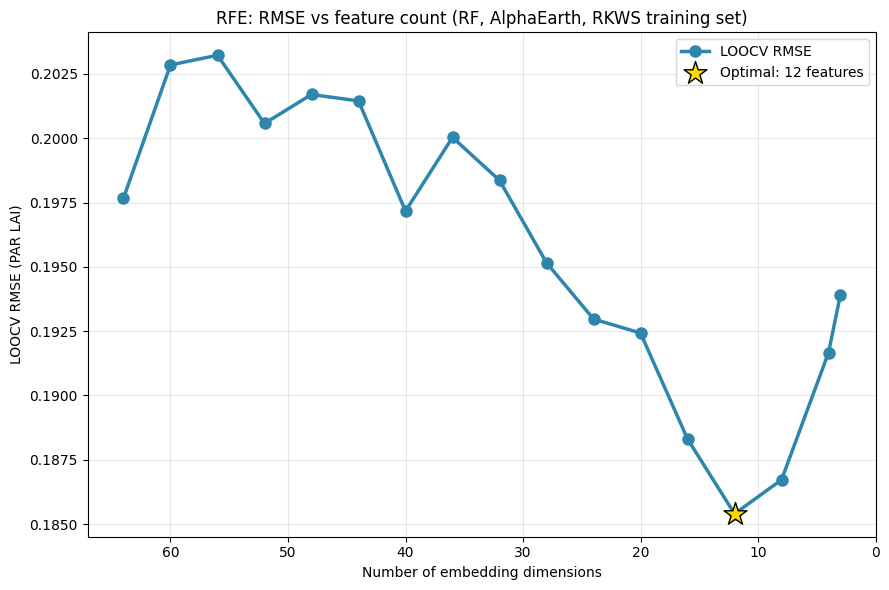

In [46]:
# %% RECURSIVE FEATURE ELIMINATION (training set only, LOOCV)
current_features = EMB_BANDS.copy()
rfe_results = []
 
if USE_RFE:
    print('\n' + '=' * 60)
    print(f'STARTING RFE ({MODEL_TAG}, RKWS training set, LOOCV)')
    print('=' * 60)
    start_time = time.time()
    iteration = 0
 
    while True:
        iteration += 1
        rmse = loocv_rmse(best_params, current_features)
        baseline = rfe_results[0]['rmse'] if rfe_results else rmse
        increase = rmse - baseline
        print(f'Iteration {iteration}: {len(current_features)} features -> '
              f'LOOCV RMSE = {rmse:.3f} (change from baseline: {increase:+.3f})')
 
        rfe_results.append({'iteration': iteration, 'n_features': len(current_features),
                            'features': current_features.copy(), 'rmse': rmse,
                            'rmse_increase': increase})
 
        if len(rfe_results) > 1 and increase > RFE_DROP_THRESHOLD:
            print(f'  STOPPING: RMSE rose by {increase:.3f} (threshold {RFE_DROP_THRESHOLD})')
            break
        if len(current_features) <= RFE_MIN_FEATURES:
            print(f'  STOPPING: reached minimum feature count ({RFE_MIN_FEATURES})')
            break
 
        model = make_model(best_params).fit(X_train_rema[current_features], y_train_rema)
        imp = feature_importance(model, X_train_rema[current_features], y_train_rema)
        ranked = [f for _, f in sorted(zip(imp, current_features))]   # least important first
        n_remove = min(RFE_STEP, len(current_features) - RFE_MIN_FEATURES)
        to_remove = ranked[:n_remove]
        print(f'  Removing: {to_remove}')
        current_features = [f for f in current_features if f not in to_remove]
 
    best_rfe = min(rfe_results, key=lambda r: r['rmse'])
    selected_features = best_rfe['features']
 
    print('\n' + '=' * 60)
    print(f'RFE COMPLETE in {(time.time() - start_time)/60:.1f} min')
    print(f'Optimal feature count: {best_rfe["n_features"]}')
    print(f'Optimal features: {selected_features}')
    print(f'Optimal LOOCV RMSE: {best_rfe["rmse"]:.3f} (baseline {rfe_results[0]["rmse"]:.3f})')
 
    rfe_df = pd.DataFrame(rfe_results)
    plt.figure(figsize=(9, 6))
    plt.plot(rfe_df['n_features'], rfe_df['rmse'], marker='o', markersize=8,
             linewidth=2.5, color='#2E86AB', label='LOOCV RMSE')
    b = rfe_df['rmse'].idxmin()
    plt.scatter(rfe_df.loc[b, 'n_features'], rfe_df.loc[b, 'rmse'], color='gold', s=300,
                marker='*', zorder=5, edgecolor='black',
                label=f'Optimal: {rfe_df.loc[b, "n_features"]} features')
    plt.xlabel('Number of embedding dimensions')
    plt.ylabel('LOOCV RMSE (PAR LAI)')
    plt.title(f'RFE: RMSE vs feature count ({MODEL_TAG}, AlphaEarth, RKWS training set)')
    plt.gca().invert_xaxis()
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    selected_features = EMB_BANDS.copy()
    print('RFE skipped: using all 64 embedding dimensions')

=== RKWS model performance (Random Forest (RF), AlphaEarth embeddings) ===
                       Set  N    R2  RMSE   MAE  rRMSE (%)  Bias (mean residual)
RKWS Train (in-sample, RF) 47 0.728 0.113 0.093        7.7                 0.006
  RKWS Test (held-out, RF) 12 0.273 0.234 0.194       15.6                -0.022

=== Per-plot residuals (RKWS test set) ===
 cluster_id  observed_par_lai  predicted_par_lai  residual
          5             1.804              1.519    -0.284
          4             2.018              1.472    -0.547
         42             1.535              1.494    -0.041
         14             1.579              1.478    -0.101
         56             1.768              1.562    -0.206
         46             1.106              1.286     0.181
         45             1.062              1.219     0.157
         31             1.640              1.522    -0.118
         58             1.399              1.545     0.145
         13             1.322              1.623

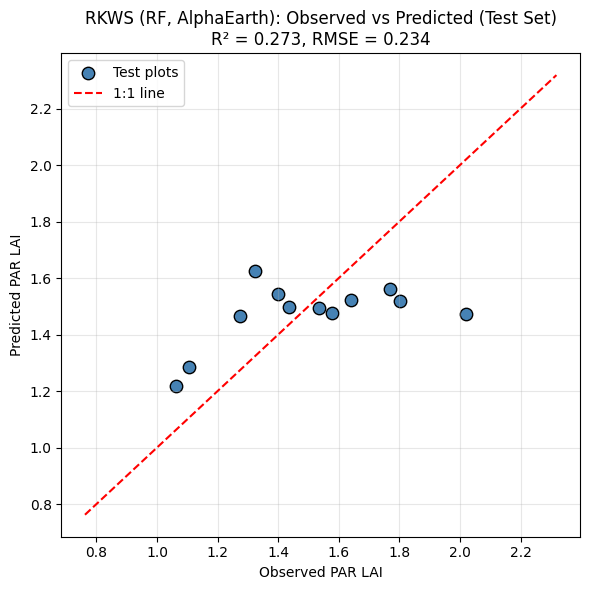

=== Spatial transfer performance (RKWS -> KNP, Random Forest (RF), AlphaEarth) ===
                                Set  N    R2  RMSE   MAE  rRMSE (%)  Bias (mean residual)
Transfer: RKWS RF -> KNP (40 plots) 40 -0.67 0.336 0.261       19.6                -0.226

=== Per-plot residuals (KNP, spatial transfer) ===
cluster_id  observed_par_lai  predicted_par_lai  residual
        20             1.925              1.540    -0.386
         2             1.549              1.396    -0.153
        27             1.569              1.420    -0.149
        40             1.649              1.481    -0.168
        11             1.584              1.547    -0.037
        13             2.051              1.533    -0.518
        25             1.891              1.421    -0.470
        32             1.486              1.534     0.048
        33             1.604              1.561    -0.043
        36             1.644              1.422    -0.222
        38             1.581              1.283

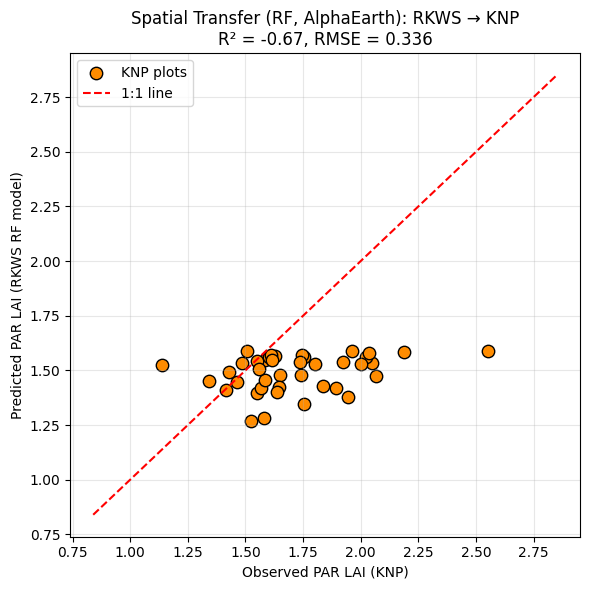

Started export: RKWS_AEF2021_RF_features
Started export: KNP_AEF2022_RF_features
  RKWS_AEF2021_RF_features: READY | KNP_AEF2022_RF_features: READY
  RKWS_AEF2021_RF_features: RUNNING | KNP_AEF2022_RF_features: COMPLETED
  RKWS_AEF2021_RF_features: RUNNING | KNP_AEF2022_RF_features: COMPLETED
RKWS_AEF2021_RF_features -> COMPLETED 
KNP_AEF2022_RF_features -> COMPLETED 
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


AssertionError: Band count 3 != feature count 12

In [47]:
# %% FINAL MODEL: FIT ON TRAINING SET, EVALUATE ON HELD-OUT TEST SET
def compute_metrics(y_true, y_pred, label):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        'Set': label,
        'N': len(y_true),
        'R2': round(r2_score(y_true, y_pred), 3),
        'RMSE': round(rmse, 3),
        'MAE': round(mean_absolute_error(y_true, y_pred), 3),
        'rRMSE (%)': round(rmse / y_true.mean() * 100, 1),
        'Bias (mean residual)': round((y_pred - y_true).mean(), 3),
    }
 
final_model = make_model(best_params)
final_model.fit(X_train_rema[selected_features], y_train_rema)
 
y_pred_train_rema = final_model.predict(X_train_rema[selected_features])
y_pred_test_rema  = final_model.predict(X_test_rema[selected_features])
 
metrics_df_rema = pd.DataFrame([
    compute_metrics(y_train_rema, y_pred_train_rema, f'RKWS Train (in-sample, {MODEL_TAG})'),
    compute_metrics(y_test_rema,  y_pred_test_rema,  f'RKWS Test (held-out, {MODEL_TAG})'),
])
print(f'=== RKWS model performance ({MODEL_NAME}, AlphaEarth embeddings) ===')
print(metrics_df_rema.to_string(index=False))
print()
 
residuals_df_rema = pd.DataFrame({
    'cluster_id': df_rema.loc[X_test_rema.index, 'cluster_id'].values,
    'observed_par_lai': y_test_rema.values.round(3),
    'predicted_par_lai': y_pred_test_rema.round(3),
    'residual': (y_pred_test_rema - y_test_rema.values).round(3),
})
print('=== Per-plot residuals (RKWS test set) ===')
print(residuals_df_rema.to_string(index=False))
print()
 
# --- Normalized permutation importance on the held-out test set (0-100) ---
perm = permutation_importance(final_model, X_test_rema[selected_features], y_test_rema,
                              n_repeats=30, random_state=42, scoring='r2')
imp_raw = perm.importances_mean
imp_clip = np.clip(imp_raw, 0, None)
imp_norm = imp_clip / imp_clip.max() * 100 if imp_clip.max() > 0 else imp_clip
 
importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Raw_Importance': imp_raw.round(4),
    'Normalized_Importance (0-100)': imp_norm.round(1),
}).sort_values('Normalized_Importance (0-100)', ascending=False).reset_index(drop=True)
print(f'=== Normalized permutation importance ({MODEL_TAG}, AlphaEarth; top 15) ===')
print(importance_df.head(15).to_string(index=False))
 
# --- Observed vs predicted (test set) ---
m_test = metrics_df_rema.iloc[1]
plt.figure(figsize=(6, 6))
plt.scatter(y_test_rema, y_pred_test_rema, color='steelblue', edgecolor='black', s=80,
            label='Test plots')
lims = [min(y_test_rema.min(), y_pred_test_rema.min()) - 0.3,
        max(y_test_rema.max(), y_pred_test_rema.max()) + 0.3]
plt.plot(lims, lims, 'r--', label='1:1 line')
plt.xlabel('Observed PAR LAI')
plt.ylabel('Predicted PAR LAI')
plt.title(f'RKWS ({MODEL_TAG}, AlphaEarth): Observed vs Predicted (Test Set)\n'
          f'R² = {m_test["R2"]}, RMSE = {m_test["RMSE"]}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
# %% NAIVE SPATIAL TRANSFER: APPLY FROZEN MODEL TO KNP (NO RETRAINING)
y_knp_true = df_knp['par_lai']
y_knp_pred = final_model.predict(df_knp[selected_features])
 
transfer_metrics_df_knp = pd.DataFrame([compute_metrics(
    y_knp_true, y_knp_pred, f'Transfer: RKWS {MODEL_TAG} -> KNP ({len(df_knp)} plots)')])
print(f'=== Spatial transfer performance (RKWS -> KNP, {MODEL_NAME}, AlphaEarth) ===')
print(transfer_metrics_df_knp.to_string(index=False))
print()
 
transfer_residuals_df_knp = pd.DataFrame({
    'cluster_id': df_knp['cluster_id'],
    'observed_par_lai': y_knp_true.round(3),
    'predicted_par_lai': y_knp_pred.round(3),
    'residual': (y_knp_pred - y_knp_true).round(3),
})
print('=== Per-plot residuals (KNP, spatial transfer) ===')
print(transfer_residuals_df_knp.to_string(index=False))
 
m_tr = transfer_metrics_df_knp.iloc[0]
plt.figure(figsize=(6, 6))
plt.scatter(y_knp_true, y_knp_pred, color='darkorange', edgecolor='black', s=80, label='KNP plots')
lims = [min(y_knp_true.min(), y_knp_pred.min()) - 0.3, max(y_knp_true.max(), y_knp_pred.max()) + 0.3]
plt.plot(lims, lims, 'r--', label='1:1 line')
plt.xlabel('Observed PAR LAI (KNP)')
plt.ylabel(f'Predicted PAR LAI (RKWS {MODEL_TAG} model)')
plt.title(f'Spatial Transfer ({MODEL_TAG}, AlphaEarth): RKWS → KNP\n'
          f'R² = {m_tr["R2"]}, RMSE = {m_tr["RMSE"]}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
# --- Save all tables ---
metrics_df_rema.to_csv(f'AEF_{MODEL_TAG}_RKWS_metrics.csv', index=False)
transfer_metrics_df_knp.to_csv(f'AEF_{MODEL_TAG}_KNP_transfer_metrics.csv', index=False)
residuals_df_rema.to_csv(f'AEF_{MODEL_TAG}_RKWS_test_residuals.csv', index=False)
transfer_residuals_df_knp.to_csv(f'AEF_{MODEL_TAG}_KNP_residuals.csv', index=False)
importance_df.to_csv(f'AEF_{MODEL_TAG}_importance.csv', index=False)
 
# %% [GEE] EXPORT EMBEDDING COMPOSITES (SELECTED DIMENSIONS) TO DRIVE
export_names = {
    'RKWS': f'RKWS_AEF{RKWS_YEAR}_{MODEL_TAG}_features',
    'KNP':  f'KNP_AEF{KNP_YEAR}_{MODEL_TAG}_features',
}
tasks = []
for site, img, bnd in [('RKWS', emb_rema, rema_boundary), ('KNP', emb_knp, knp_boundary)]:
    task = ee.batch.Export.image.toDrive(
        image=img.select(selected_features).toFloat(),   # band order = selected_features
        description=export_names[site],
        folder=DRIVE_FOLDER,
        fileNamePrefix=export_names[site],
        region=bnd.geometry(),
        scale=10,
        crs='EPSG:4326',
        maxPixels=1e13,
    )
    task.start()
    tasks.append(task)
    print('Started export:', export_names[site])
 
# Wait for both exports (re-run this loop if Colab times out)
while any(t.status()['state'] in ('READY', 'RUNNING') for t in tasks):
    print('  ' + ' | '.join(f"{t.status()['description']}: {t.status()['state']}" for t in tasks))
    time.sleep(30)
for t in tasks:
    s = t.status()
    print(s['description'], '->', s['state'], s.get('error_message', ''))
 
# %% [DRIVE] PREDICT LAI MAPS FROM THE EXPORTED RASTERS
import rasterio
from google.colab import drive
drive.mount('/content/drive')
 
def predict_lai_map(tif_path, out_path, model, feature_names):
    with rasterio.open(tif_path) as src:
        arr = src.read().astype('float32')            # (bands, rows, cols)
        profile = src.profile
    n_bands, rows, cols = arr.shape
    assert n_bands == len(feature_names), f'Band count {n_bands} != feature count {len(feature_names)}'
 
    X = arr.reshape(n_bands, -1).T                     # (pixels, bands)
    valid = np.all(np.isfinite(X), axis=1)
    pred = np.full(X.shape[0], np.nan, dtype='float32')
    pred[valid] = model.predict(pd.DataFrame(X[valid], columns=feature_names))
    lai_map = pred.reshape(rows, cols)
 
    profile.update(count=1, dtype='float32', nodata=np.nan, compress='lzw')
    with rasterio.open(out_path, 'w', **profile) as dst:
        dst.write(lai_map, 1)
    return lai_map
 
lai_rkws = predict_lai_map(base + export_names['RKWS'] + '.tif',
                           base + f'RKWS_LAI_pred_AEF_{MODEL_TAG}.tif',
                           final_model, selected_features)
lai_knp = predict_lai_map(base + export_names['KNP'] + '.tif',
                          base + f'KNP_LAI_pred_AEF_{MODEL_TAG}.tif',
                          final_model, selected_features)      # frozen model, no retraining
 
# --- Quick-look maps (aspect-corrected for geographic pixels) ---
def pixel_size_m(path):
    with rasterio.open(path) as src:
        dx, dy = src.transform.a, -src.transform.e
        if src.crs.is_geographic:
            lat0 = np.radians((src.bounds.top + src.bounds.bottom) / 2)
            return dx * 111320 * np.cos(lat0), dy * 111320
        return dx, dy
 
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, m, site, label in zip(axes, [lai_rkws, lai_knp], ['RKWS', 'KNP'], ['(a)', '(b)']):
    mx, my = pixel_size_m(base + export_names[site] + '.tif')
    im = ax.imshow(m, cmap='YlGn', vmin=0, vmax=6, aspect=my / mx)
    ax.axis('off')
    ax.set_anchor('N')
    ax.text(0.02, 0.98, label, transform=ax.transAxes, fontsize=16,
            fontweight='bold', va='top', ha='left')
fig.colorbar(im, ax=axes, shrink=0.7, label=f'Predicted PAR LAI (AlphaEarth, {MODEL_TAG})')
plt.savefig(base + f'LAI_maps_RKWS_KNP_AEF_{MODEL_TAG}.png', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()
 
# %% [DRIVE] SUMMARY STATISTICS OF PREDICTED LAI MAPS
map_rows = []
for site, m in [('RKWS', lai_rkws), ('KNP', lai_knp)]:
    mx, my = pixel_size_m(base + export_names[site] + '.tif')
    vals = m[np.isfinite(m)]
    map_rows.append({
        'Predictors (model)': f'AlphaEarth ({MODEL_TAG})', 'Site': site,
        'Area (ha)': round(len(vals) * mx * my / 10000, 1),
        'Min': round(vals.min(), 2), 'Max': round(vals.max(), 2),
        'Range': round(vals.max() - vals.min(), 2),
        'Mean': round(vals.mean(), 2), 'SD': round(vals.std(), 2),
        'CV (%)': round(vals.std() / vals.mean() * 100, 1),
    })
map_stats_df = pd.DataFrame(map_rows)
print(f'=== Predicted LAI summary (AlphaEarth, {MODEL_TAG}) ===')
print(map_stats_df.to_string(index=False))
map_stats_df.to_csv(base + f'LAI_summary_stats_AEF_{MODEL_TAG}.csv', index=False)